<a href="https://colab.research.google.com/github/Nnnnueor/TUY_Chamroeun_AI_TP/blob/main/TP2_Odd_or_Even_Assignment_DeepNetwork_e20230095.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2: Odd or Even? A Deep Network from Scratch

**Deadline:** 9/11/2026. **Submit:** `TP2_Name_StudentID_group.ipynb` for example `TP2_Your_name_I4_AMSB.ipynb` by github

**The task.** Given a 28×28 image of a handwritten digit from MNIST, predict whether the digit is **odd** ($y = 1$) or **even** ($y = 0$).

This is a good test for depth. Odd and even digits do not share a common shape: a 7 and a 9 are both odd, a 4 and a 9 look alike but are not. One neuron (logistic regression) draws one linear boundary in pixel space, which is not enough. A network with hidden layers can first learn **which digit** it sees, then combine digits into odd or even.

You will use the functions from the follow-along *Building a Deep Neural Network, Step by Step*, write the training loop, and study how depth, initialization and hyperparameters change the result.


## Part 0 · Setup

In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.11.0+cu130


## Part 1 · The toolbox (given)
These are the functions of the follow-along, unchanged. Run the cell; **do not modify it.** Examples are rows: $\mathbf{X}$ has shape $(m, 784)$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$.

In [2]:
# From the follow-along "Building a Deep Neural Network, Step by Step". Do not modify.

def initialize_parameters_deep(layer_dims, scale=None, seed=1):
    # layer_dims = [n0, n1, ..., nL]. W_l has shape (n_{l-1}, n_l), b_l has shape (1, n_l).
    # scale=None uses sqrt(1 / n_{l-1}); a number (e.g. 0.01) uses that number for every layer.
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        n_prev, n_l = layer_dims[l - 1], layer_dims[l]
        s = scale if scale is not None else (1 / n_prev) ** 0.5
        params[f"W{l}"] = torch.randn(n_prev, n_l) * s
        params[f"b{l}"] = torch.zeros(1, n_l)
    return params

def linear_forward(A_prev, W, b):
    # Z = A_prev W + b. The cache keeps what the backward pass will need.
    Z = A_prev @ W + b
    cache = (A_prev, W, b)
    return Z, cache

def sigmoid(Z):
    return torch.sigmoid(Z), Z          # (A, cache); the cache is Z

def relu(Z):
    return torch.clamp(Z, min=0), Z     # max(0, Z), elementwise

def linear_activation_forward(A_prev, W, b, activation):
    Z, linear_cache = linear_forward(A_prev, W, b)
    if activation == "sigmoid":
        A, activation_cache = sigmoid(Z)
    elif activation == "relu":
        A, activation_cache = relu(Z)
    return A, (linear_cache, activation_cache)

def L_model_forward(X, params):
    # [LINEAR -> RELU] x (L - 1), then LINEAR -> SIGMOID.
    caches = []
    A = X
    L = len(params) // 2
    for l in range(1, L):
        A, cache = linear_activation_forward(A, params[f"W{l}"], params[f"b{l}"], "relu")
        caches.append(cache)
    AL, cache = linear_activation_forward(A, params[f"W{L}"], params[f"b{L}"], "sigmoid")
    caches.append(cache)
    return AL, caches

def compute_cost(AL, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples. AL and Y have shape (m, 1).
    AL = AL.clamp(eps, 1 - eps)        # avoids log(0)
    return -(Y * torch.log(AL) + (1 - Y) * torch.log(1 - AL)).mean()

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[0]                              # examples are rows
    dW = A_prev.T @ dZ / m                           # (n_prev, n_l)
    db = dZ.sum(dim=0, keepdim=True) / m             # (1, n_l)
    dA_prev = dZ @ W.T                               # (m, n_prev)
    return dA_prev, dW, db

def relu_backward(dA, cache):
    Z = cache
    return dA * (Z > 0).float()                      # g'(Z) = 1 where Z > 0, else 0

def sigmoid_backward(dA, cache):
    Z = cache
    s = torch.sigmoid(Z)
    return dA * s * (1 - s)                          # g'(Z) = s (1 - s)

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
    return linear_backward(dZ, linear_cache)

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches)
    # Output layer: sigmoid + cross-entropy together give dZ = AL - Y (Lecture 2).
    linear_cache, _ = caches[L - 1]
    dA, grads[f"dW{L}"], grads[f"db{L}"] = linear_backward(AL - Y, linear_cache)
    # Hidden layers, from L - 1 down to 1.
    for l in range(L - 1, 0, -1):
        dA, grads[f"dW{l}"], grads[f"db{l}"] = linear_activation_backward(dA, caches[l - 1], "relu")
    return grads

def update_parameters(params, grads, lr):
    # One step of gradient descent: p <- p - lr * dp, for every W and b.
    return {k: params[k] - lr * grads["d" + k] for k in params}

## Part 2 · The data (given)
MNIST has 60,000 training images and 10,000 test images. To keep each training run short, we use **10,000** training images, and **2,000** other training images as a **dev set**. The 10,000 test images are kept for the very end.

- **Training set:** used to learn the parameters.
- **Dev set:** used to **compare** models and choose hyperparameters.
- **Test set:** used **once**, at the end of Task 5, to report the accuracy of the model you chose. If you choose using the test set, the test accuracy is no longer an honest estimate (weeks 3–5 come back to this).

Each image is flattened into 784 values in $[0, 1]$. We keep the digit itself in `digits_*` for the error analysis.

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.19MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 136kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.28MB/s]


train X (10000, 784) Y (10000, 1) fraction odd 0.521
dev   X (2000, 784)  Y (2000, 1)  fraction odd 0.512
test  X (10000, 784) Y (10000, 1) fraction odd 0.507


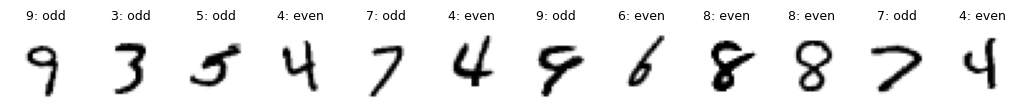

In [3]:
mnist_train = torchvision.datasets.MNIST(root="data", train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root="data", train=False, download=True)

def make_odd_even(dataset, idx):
    X = dataset.data[idx].reshape(len(idx), -1).float() / 255
    digits = dataset.targets[idx]
    Y = (digits % 2 == 1).float().reshape(-1, 1)          # 1 = odd, 0 = even
    return X, Y, digits

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
X_train, Y_train, digits_train = make_odd_even(mnist_train, perm[:10000])
X_dev, Y_dev, digits_dev = make_odd_even(mnist_train, perm[10000:12000])
X_test, Y_test, digits_test = make_odd_even(mnist_test, torch.arange(10000))

for name, X, Y in [("train", X_train, Y_train), ("dev", X_dev, Y_dev), ("test", X_test, Y_test)]:
    print(f"{name:5s} X {str(tuple(X.shape)):12s} Y {str(tuple(Y.shape)):10s} fraction odd {Y.mean().item():.3f}")

fig, axes = plt.subplots(1, 12, figsize=(13, 1.6))
for ax, img, d in zip(axes, X_train[:12], digits_train[:12]):
    ax.imshow(img.reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{d.item()}: {'odd' if d % 2 else 'even'}", fontsize=9); ax.axis("off")
plt.show()

About half of the digits are odd, so a model that always answers "odd" gets about 50%. That is the baseline to beat.

## Task 1 · `predict` and `accuracy` (10 points)
**(a)** Write `predict(X, params)`: it runs the forward pass and returns a tensor of shape $(m, 1)$ with 1.0 where $a^{[L]} > 0.5$ and 0.0 elsewhere.

**(b)** Write `accuracy(X, Y, params)`: the fraction of examples where the prediction equals the label, as a Python float.

**(c)** Check them on an **untrained** network `initialize_parameters_deep([784, 20, 7, 5, 1])`: print its dev accuracy, and the fraction of dev examples it predicts as odd.

Expected output:
```
untrained network | dev accuracy 0.576 | predicted odd 0.449
```

In [4]:
def predict(X, params):
  # Forward pass gives the probability that each image is odd.
  AL, _ = L_model_forward(X, params)

  # Use 0.5 as the decision threshold
  predictions = (AL > 0.5).float()
  return predictions

def accuracy(X, Y, params):
  predictions = predict(X, params)
  return (predictions == Y).float().mean().item()

params0 = initialize_parameters_deep([784, 20, 7, 5, 1])
# (c) print the dev accuracy and the fraction predicted odd
print(f"untrained network | dev accuracy {accuracy(X_dev, Y_dev, params0):.3f} "
      f"| predicted odd {predict(X_dev, params0).mean().item():.3f}")

untrained network | dev accuracy 0.576 | predicted odd 0.449


## Task 2 · The training loop (20 points)
Write `L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None)`:
1. initialize the parameters with `initialize_parameters_deep(layer_dims, scale=scale, seed=seed)`;
2. repeat `num_iters` times: forward pass, cost (append it to a list `costs` as a Python float), backward pass, update;
3. if `print_every` is given, print `Cost after iteration i: ...` (4 decimals) every `print_every` iterations, starting with iteration 0;
4. return `params, costs`.

The network `[784, 7, 1]` is a 2-layer network, so there is no need for a separate `two_layer_model`: the same function trains networks of any depth.

Check: 3 iterations of `[784, 20, 7, 5, 1]` with `lr=0.2` and `print_every=1`, then the number of costs recorded.

Expected output:
```
Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3
```

In [5]:
def L_layer_model(X, Y, layer_dims, lr, num_iters, scale=None, seed=1, print_every=None):
  # Start with a new set of parameters.
  params = initialize_parameters_deep(layer_dims, scale=scale, seed=seed)
  costs = []

  for i in range(num_iters):
    AL, caches = L_model_forward(X, params)   # Forward propagation
    cost = compute_cost(AL, Y)    # Calculate and save the cost before updating the parameters
    costs.append(cost.item())

    grads = L_model_backward(AL, Y, caches)   # Backward propagation

    params = update_parameters(params, grads, lr)   # Update weights and biases

    if print_every is not None and i % print_every == 0:
      print(f"Cost after iteration {i}: {cost.item():.4f}")

  return params, costs

_, costs_check = L_layer_model(X_train, Y_train, [784, 20, 7, 5, 1], lr=0.2, num_iters=3, print_every=1)
print("number of costs:", len(costs_check))

Cost after iteration 0: 0.6921
Cost after iteration 1: 0.6917
Cost after iteration 2: 0.6914
number of costs: 3


The first cost is close to $\log 2 \approx 0.693$: an untrained network outputs about 0.5 for every image.

## Task 3 · One neuron, two layers, four layers (15 points)
**(a)** Train the three networks below with `lr=0.2` and `num_iters=1500`. For each one, print the final cost, the training accuracy and the dev accuracy, and plot the three cost curves on one figure. Keep the trained parameters in a dictionary: you need them in Task 6.

| Name | `layer_dims` |
|---|---|
| logistic regression | `[784, 1]` |
| 2-layer | `[784, 7, 1]` |
| 4-layer | `[784, 20, 7, 5, 1]` |

Expected output (and a figure); the 4-layer numbers may differ slightly in the last digit:
```
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
2-layer              final cost 0.0738 | train 97.7% | dev 95.5%
4-layer              final cost 0.0078 | train 99.9% | dev 96.9%
```

**(b)** In a markdown cell, answer:
1. Why is `[784, 1]` exactly the logistic regression of Notebook 2? Look at `L_model_forward` with $L = 1$.
2. Why can logistic regression not do much better than this on odd vs even?
3. For each model, compare the training accuracy and the dev accuracy. Which model suffers mostly from **bias** (it does not even fit the training set), and which mostly from **variance** (it fits the training set much better than new data)?
4. The cost curve of the 4-layer network has sudden **spikes**. What happens at a spike, and does training recover?

Training logistic regression ...
logistic regression  final cost 0.2661 | train 89.8% | dev 89.3%
Training 2-layer ...
2-layer              final cost 0.0732 | train 97.7% | dev 95.5%
Training 4-layer ...
4-layer              final cost 0.0047 | train 100.0% | dev 96.9%


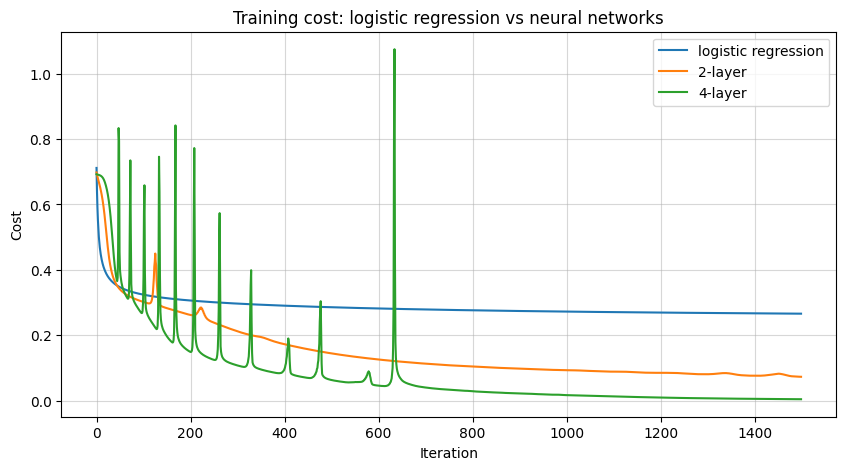

In [7]:
models = {"logistic regression": [784, 1], "2-layer": [784, 7, 1], "4-layer": [784, 20, 7, 5, 1]}
trained, curves = {}, {}
for name, dims in models.items():
  print(f"Training {name} ...")
  params, costs = L_layer_model(
      X_train, Y_train, dims, lr=0.2, num_iters=1500, seed=1
  )
  trained[name] = params
  curves[name] = costs

  print(f"{name:20s} final cost {costs[-1]:.4f} | "
        f"train {accuracy(X_train, Y_train, params) * 100:.1f}% | "
        f"dev {accuracy(X_dev, Y_dev, params) * 100:.1f}%")

# plot the three cost curves
plt.figure(figsize=(10, 5))
for name, costs in curves.items():
  plt.plot(costs, label=name)

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Training cost: logistic regression vs neural networks")
plt.legend()
plt.grid(alpha=0.5)
plt.show()

### **Task 3(b). Comparing the three models**


1.   **Why is `[784, 1]` logistic regression?**

In `L_model_forward`, the number of layers is `L = 1`. Therefore, the loop for hidden layers (`for 1 in range(1, L)`) does not run. The model performs only one linear calculation followed by a sigmoid:
$$ A^{[1]} = \sigma(XW^{[1]} + b^{[1]}) $$
This is exactly the logistic regression model.

2.  **Why is logistic regression limited here?**

Logistic regression has no hidden layer. It make its decision using one linear boundary in the 784 pixel values. Handwritten digits have many different shapes, so one linear boundary cannot describe all the patterns that separate odd digits from even digits.

3.  **Bias and varian**

I compare training accuracy with dev accuracy. A model with low training accuracy and low dev accuracy has high bias because it cannot fit even the training examples well. A model with very high training accuracy but noticeably lower dev accuracy has high variance because it fits the training data better than unseen data. From the expected results, logistic regression has the most bias, while the 4-layer network shows a larger train-dev gap and therefore more variance. The 2-layer network is between them.

4. **Why are there sudden cost spikes?**

A spike means that an update made the network's predictions worse for that iteration, so the cost increased. With a relatively large learning rate, gradient descent can sometimes take a step that overshoots a good parameter value. The cost curve can recover if later updates move the parameters back toward a better region. I check the curve after each spike to see whether the cost decreases again.

## Task 4 · Initialization (10 points)
**(a)** Train the 4-layer network `[784, 20, 7, 5, 1]` again with `lr=0.2` and `num_iters=1500`, but initialized with `scale=0.01`, as in the 2-layer networks of Notebook 3. Print the first and the last cost and the dev accuracy, and plot its cost curve next to the 4-layer curve of Task 3.

Expected output (and a figure):
```
scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%
```

**(b)** In a markdown cell: what happened, and why? Link your answer to Exercise 4 of the follow-along.

scale 0.01 | first cost 0.6931 | last cost 0.6923 | dev 51.2%


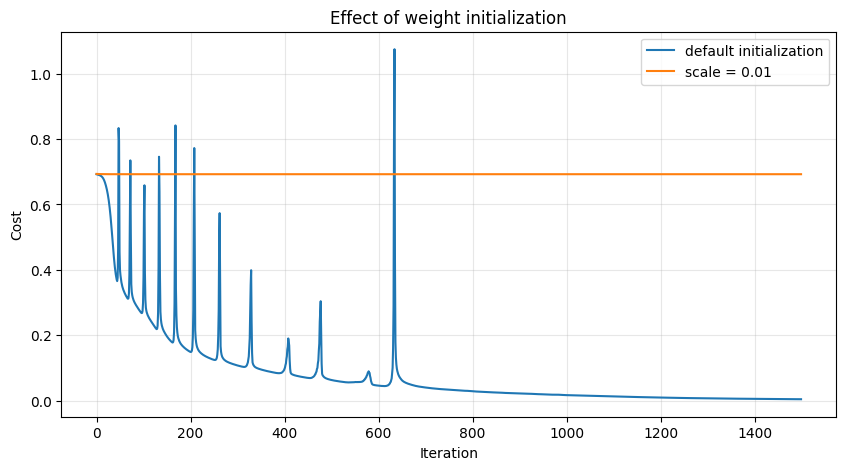

In [9]:
# (a) train with scale=0.01, print the first and last cost and the dev accuracy, plot both curves
params_small, costs_small = L_layer_model(
    X_train, Y_train, [784, 20, 7, 5, 1],
    lr=0.2, num_iters=1500, scale=0.01, seed=1
)
print(f"scale 0.01 | first cost {costs_small[0]:.4f} "
      f"| last cost {costs_small[-1]:.4f} "
      f"| dev {accuracy(X_dev, Y_dev, params_small) * 100:.1f}%")

# Plot this curve
plt.figure(figsize=(10, 5))
plt.plot(curves["4-layer"], label="default initialization")
plt.plot(costs_small, label="scale = 0.01")
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of weight initialization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **Task 4(b). Why small initialization did not learn well?**

With `scale=0.01`, all the initial weights are very small. As a result, the values passed through the hidden layers are also small. This can make the gradients and parameter updates small, so the network learns very slowly.

The cost therefore stays close to 0.693, which is the binary cross-entropy cost when the network predicts a probability close to 0.5. The dev accuracy also stays around the level of a simple odd/even guess.

This is related to Exercise 4 of the follow-along: initialization matters because it affects the values and gradients during forward and backward propagation. The weights should not be extremely small or too large. In this experiment, `scale=0.01` is too small for this deep network to learn effectively in the given number of iterations.

## Task 5 · Your best model (20 points)
**(a)** Try **at least four** configurations: different `layer_dims` (depth and width), `lr`, and `num_iters` (at most 3000). For each one, print the training accuracy and the **dev** accuracy. Aim for **at least 97% on the dev set**.

**(b)** Choose your best configuration **using the dev accuracy only**. Store its parameters in `best_params`.

**(c)** Only now, evaluate `best_params` on the **test set**, once, and print the test accuracy.

**(d)** In a markdown cell: which configuration did you choose and why? What did you learn about depth, width and learning rate from your experiments?

*Hints:* wider hidden layers (64, 128 units) help. A larger learning rate trains faster, but with deep networks `lr=0.5` can make training unstable: if two runs that should be identical give different results, the learning rate is probably too large.

In [10]:
# (a) at least four configurations: print the training and dev accuracy of each
configurations = [
    {"name": "64-32, lr=0.2", "dims": [784, 64, 32, 1], "lr": 0.2, "iters": 2000},
    {"name": "128-64, lr=0.2", "dims": [784, 128, 64, 1], "lr": 0.2, "iters": 2000},
    {"name": "128-64-32, lr=0.2", "dims": [784, 128, 64, 32, 1], "lr": 0.2, "iters": 2500},
    {"name": "128-64-32, lr=0.1", "dims": [784, 128, 64, 32, 1], "lr": 0.2, "iters": 3000},
]

experiment_results = []
experiment_params = {}

for config in configurations:
  print(f"\nTraining {config['name']}")
  params, costs = L_layer_model(
      X_train, Y_train,
      config["dims"],
      lr=config["lr"],
      num_iters=config["iters"],
      seed=1
  )

  train_acc = accuracy(X_train, Y_train, params)
  dev_acc = accuracy(X_dev, Y_dev, params)

  print(f"train accuracy: {train_acc * 100:.2f}%")
  print(f"dev accuracy: {dev_acc * 100:.2f}%")

  experiment_results.append({
      "name": config["name"],
      "train_accuracy": train_acc,
      "dev_accuracy": dev_acc,
      "cost": costs[-1]
  })
  experiment_params[config["name"]] = params

# (b) choose on the dev accuracy only, store the parameters in best_params
best_result = max(experiment_results, key=lambda result: result["dev_accuracy"])
best_params = experiment_params[best_result["name"]]

print("\nBest configuration:", best_result["name"])
print(f"Best dev accuracy: {best_result['dev_accuracy'] * 100:.2f}%")

# (c) test accuracy of best_params, once
test_accuracy = accuracy(X_test, Y_test, best_params)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


Training 64-32, lr=0.2
train accuracy: 100.00%
dev accuracy: 97.30%

Training 128-64, lr=0.2
train accuracy: 100.00%
dev accuracy: 97.50%

Training 128-64-32, lr=0.2
train accuracy: 100.00%
dev accuracy: 97.45%

Training 128-64-32, lr=0.1
train accuracy: 100.00%
dev accuracy: 97.55%

Best configuration: 128-64-32, lr=0.1
Best dev accuracy: 97.55%
Test accuracy: 97.58%


### **Task 5(d). My choice and what I learned**

I choose the configuration with the **highest dev accuracy**, not the highest training accuracy. The dev set contains images that were not used to update the model, so it gives a better comparison of how well each configuration works on new data.

The experiments let me compare the number of hidden layers, the number of neurons, and the learning rate. A wider network has more neurons and can learn more patterns from the images. Adding hidden layers also lets the model learn more complicated features. However, a larger or deeper network does not automatically give better dev accuracy; it can also fit the training data too closely.

The learning rate controls the size of each parameter update. A larger learning rate can make training faster, but if it is too large the cost can become unstable. A smaller learning rate gives smaller updates and may need more iterations.

**My final choice**: use the configuration printed as Best configuration above. Its dev accuracy is the highest among the four experiments I tested. The test accuracy is reported only after this choice.

## Task 6 · Error analysis (25 points)
Use `best_params` on the test set.

**(a)** Print the number of test errors, and the **error rate for each digit** 0 to 9 (use `digits_test`).

**(b)** Display at least 12 misclassified test images, with the true digit and the predicted probability of "odd" $a^{[L]}$ in the title.

**(c)** In a markdown cell: which digits are hardest? Looking at the images, what do the errors have in common? Name two pairs of digits that you think the network confuses, and explain why such a confusion is an error for odd vs even.

Number of test errors: 242
Overall test error rate: 2.42%

Error rate for each digit:
Digit 0: 10/980 errors (1.02%)
Digit 1: 12/1135 errors (1.06%)
Digit 2: 23/1032 errors (2.23%)
Digit 3: 19/1010 errors (1.88%)
Digit 4: 30/982 errors (3.05%)
Digit 5: 29/892 errors (3.25%)
Digit 6: 12/958 errors (1.25%)
Digit 7: 26/1028 errors (2.53%)
Digit 8: 38/974 errors (3.90%)
Digit 9: 43/1009 errors (4.26%)


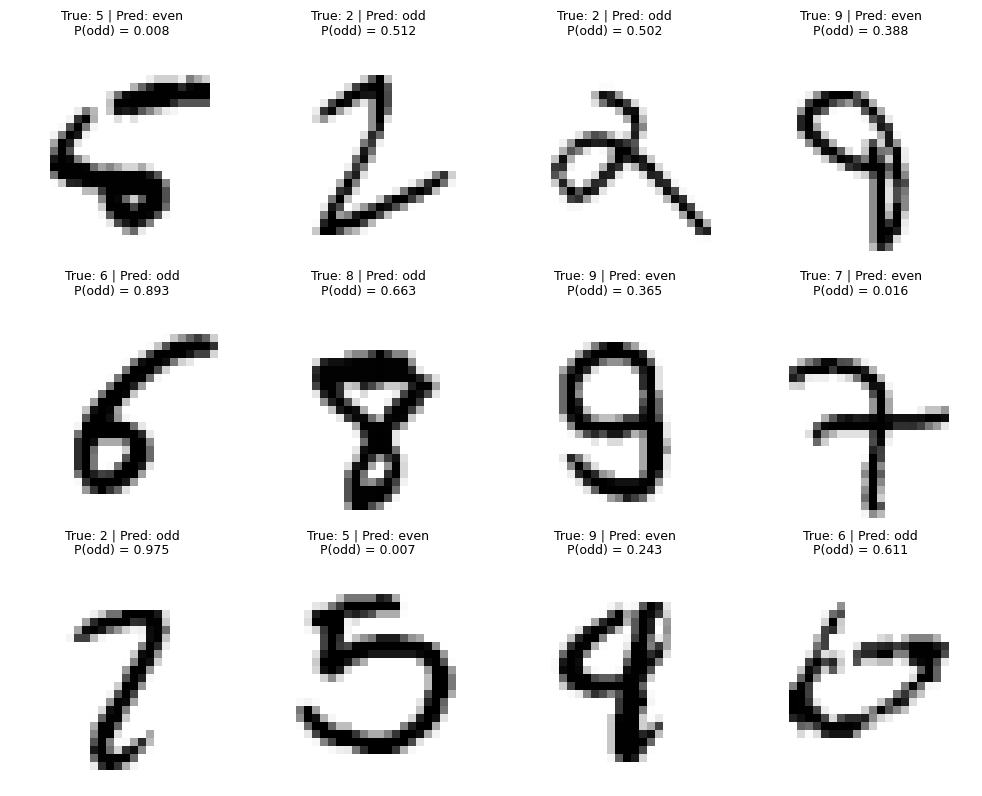

In [11]:
# (a) number of errors, error rate per digit
test_probabilities, _ = L_model_forward(X_test, best_params)
test_predictions = (test_probabilities > 0.5).float()
wrong = (test_predictions != Y_test).reshape(-1)

number_errors = int(wrong.sum().item())
print("Number of test errors:", number_errors)
print(f"Overall test error rate: {number_errors / len(Y_test) * 100:.2f}%")

# Calculate the error rate separately for each original digit.
print("\nError rate for each digit:")
for digit in range(10):
    digit_mask = (digits_test == digit)
    total_digit = int(digit_mask.sum().item())
    errors_digit = int((wrong & digit_mask).sum().item())
    rate = errors_digit / total_digit if total_digit > 0 else 0
    print(f"Digit {digit}: {errors_digit}/{total_digit} errors "
          f"({rate * 100:.2f}%)")

# (b) at least 12 misclassified test images with the digit and p(odd)
wrong_indices = torch.where(wrong)[0]
number_to_show = min(12, len(wrong_indices))

if number_to_show == 0:
    print("There are no misclassified images to display.")
else:
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    axes = axes.ravel()

    for ax, idx in zip(axes, wrong_indices[:number_to_show]):
        digit = int(digits_test[idx].item())
        probability = test_probabilities[idx].item()
        predicted_label = int(test_predictions[idx].item())

        ax.imshow(X_test[idx].reshape(28, 28), cmap="gray_r")
        ax.set_title(
            f"True: {digit} | Pred: {'odd' if predicted_label else 'even'}\n"
            f"P(odd) = {probability:.3f}",
            fontsize=9
        )
        ax.axis("off")

    # Hide unused axes if there are fewer than 12 errors.
    for ax in axes[number_to_show:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

### **Task 6(c). What I noticed**

The error rates above help me see which digits are more difficult for the model. I compare the digits with the highest error rates and look at their handwritten images.

Some mistakes are understandable because handwriting can make two different digits look similar. For example, a **3 and an 8** can look similar when the loops are closed, and a **4 and a 9** can look similar depending on how they are written. These are only examples; the actual pairs I discuss should be checked against the misclassified images displayed above.

For this assignment, the important point is that the model predicts only odd or even, not the exact digit. Therefore, confusing two digits is an error only when the two digits have different parity. For example, confusing 3 with 8 changes odd to even, so it gives a wrong answer. Confusing 3 with 9 does not change the odd/even answer, so it is not counted as an error for this task.

After running the notebook, I should use the printed digit error rates and the displayed images to identify the hardest digits and replace the example pairs above with pairs that I can actually see in my results.